In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.stats.weightstats import ztest
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

#Splitting data
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
print("Data loaded successfully! ")

print(train_df)
print(test_df)

Data loaded successfully! 
        Unnamed: 0      id  Gender      Customer Type  Age   Type of Travel  \
0                0   70172    Male     Loyal Customer   13  Personal Travel   
1                1    5047    Male  disloyal Customer   25  Business travel   
2                2  110028  Female     Loyal Customer   26  Business travel   
3                3   24026  Female     Loyal Customer   25  Business travel   
4                4  119299    Male     Loyal Customer   61  Business travel   
...            ...     ...     ...                ...  ...              ...   
103899      103899   94171  Female  disloyal Customer   23  Business travel   
103900      103900   73097    Male     Loyal Customer   49  Business travel   
103901      103901   68825    Male  disloyal Customer   30  Business travel   
103902      103902   54173  Female  disloyal Customer   22  Business travel   
103903      103903   62567    Male     Loyal Customer   27  Business travel   

           Class  Flight

In [35]:
#Data Cleaning

#Deleting Useless ID Columns
train_df = train_df.drop(columns=['Unnamed: 0', 'id'], errors='ignore')
test_df = test_df.drop(columns=['Unnamed: 0', 'id'], errors='ignore')

# Fill missing Arrival Delays with the median  value
train_df['Arrival Delay in Minutes'] = train_df['Arrival Delay in Minutes'].fillna(train_df['Arrival Delay in Minutes'].median())
test_df['Arrival Delay in Minutes'] = test_df['Arrival Delay in Minutes'].fillna(test_df['Arrival Delay in Minutes'].median())

# 3. Convert text to numbers
safe_mapping = {
    'neutral or dissatisfied': 0, 'satisfied': 1,
    'Male': 0, 'Female': 1,
    'disloyal Customer': 0, 'Loyal Customer': 1,
    'Personal Travel': 0, 'Business travel': 1,
    'Eco': 0, 'Eco Plus': 1, 'Business': 2
}

train_df = train_df.replace(safe_mapping)
test_df = test_df.replace(safe_mapping)

train_df = train_df.fillna(0)
test_df = test_df.fillna(0)

print("Data Cleaned Successfully!")
display(train_df.head(10))


Data Cleaned Successfully!


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,1,13,0,1,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,0
1,0,0,25,1,2,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,0
2,1,1,26,1,2,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,1
3,1,1,25,1,2,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,0
4,0,1,61,1,2,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,1
5,1,1,26,0,0,1180,3,4,2,1,...,1,3,4,4,4,4,1,0,0.0,0
6,0,1,47,0,0,1276,2,4,2,3,...,2,3,3,4,3,5,2,9,23.0,0
7,1,1,52,1,2,2035,4,3,4,4,...,5,5,5,5,4,5,4,4,0.0,1
8,1,1,41,1,2,853,1,2,2,2,...,1,1,2,1,4,1,2,0,0.0,0
9,0,0,20,1,0,1061,3,3,3,4,...,2,2,3,4,4,3,2,0,0.0,0


In [36]:
#Central Tendency
num_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes']

print("\nMEAN:")
print(train_df[num_cols].mean().round(2))

print("\nMEDIAN:")
print(train_df[num_cols].median())

print("\nMODE:")
print(train_df[num_cols].mode().iloc[0])

print("\nDESCRIBE: ")
print(train_df.describe())


MEAN:
Age                             39.38
Flight Distance               1189.45
Departure Delay in Minutes      14.82
dtype: float64

MEDIAN:
Age                            40.0
Flight Distance               843.0
Departure Delay in Minutes      0.0
dtype: float64

MODE:
Age                            39
Flight Distance               337
Departure Delay in Minutes      0
Name: 0, dtype: int64

DESCRIBE: 
                 Age  Flight Distance  Inflight wifi service  \
count  103904.000000    103904.000000          103904.000000   
mean       39.379706      1189.448375               2.729683   
std        15.114964       997.147281               1.327829   
min         7.000000        31.000000               0.000000   
25%        27.000000       414.000000               2.000000   
50%        40.000000       843.000000               3.000000   
75%        51.000000      1743.000000               4.000000   
max        85.000000      4983.000000               5.000000   

       Depar

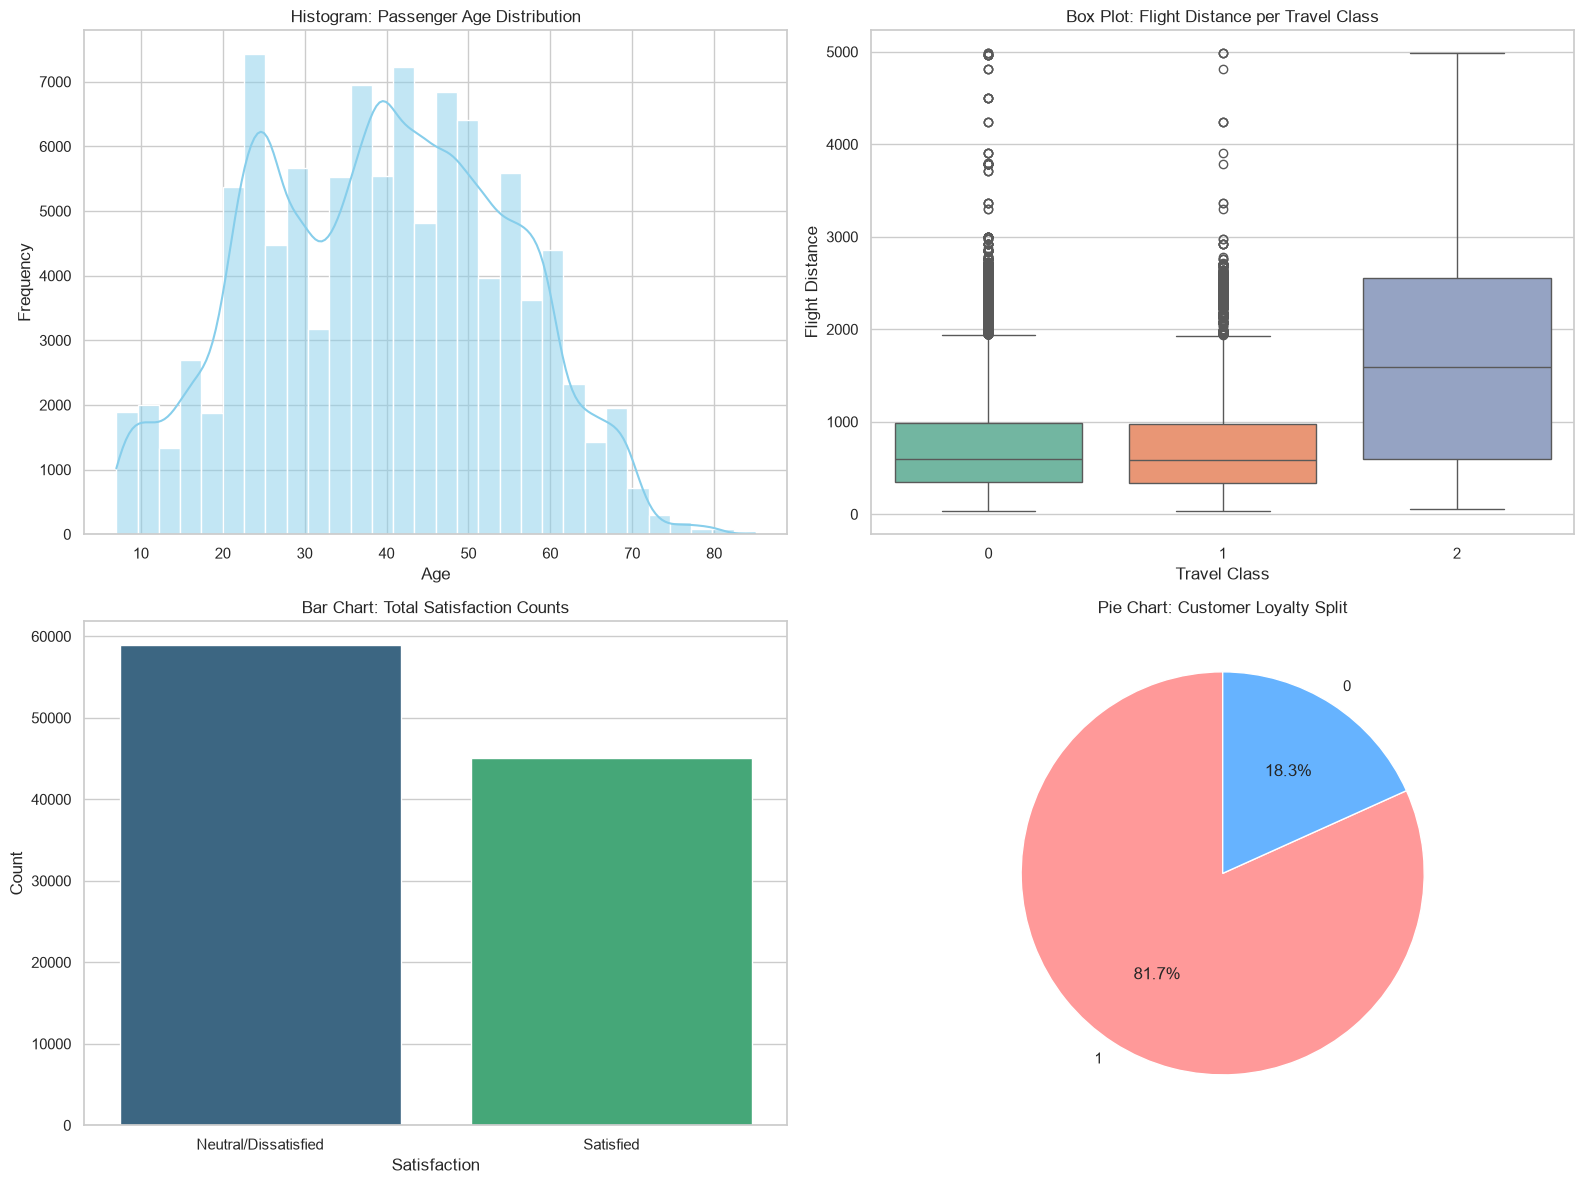

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram: Age Distribution
sns.histplot(
    train_df['Age'],
    bins=30,
    kde=True,
    ax=axes[0, 0],
    color='skyblue'
)
axes[0, 0].set_title('Histogram: Passenger Age Distribution')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')


# 2. Box Plot: Flight Distance by Class
sns.boxplot(
    x='Class',
    y='Flight Distance',
    data=train_df,
    hue='Class',
    palette='Set2',
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Box Plot: Flight Distance per Travel Class')
axes[0, 1].set_xlabel('Travel Class')
axes[0, 1].set_ylabel('Flight Distance')


# 3. Bar Chart: Satisfaction Count
sns.countplot(
    x='satisfaction',
    data=train_df,
    hue='satisfaction',
    palette='viridis',
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Bar Chart: Total Satisfaction Counts')
axes[1, 0].set_xlabel('Satisfaction')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(['Neutral/Dissatisfied', 'Satisfied'])


# 4. Pie Chart: Customer Type
customer_counts = train_df['Customer Type'].value_counts()

axes[1, 1].pie(
    customer_counts,
    labels=customer_counts.index,
    autopct='%1.1f%%',
    colors=['#ff9999', '#66b3ff'],
    startangle=90
)
axes[1, 1].set_title('Pie Chart: Customer Loyalty Split')
plt.tight_layout()
plt.show()

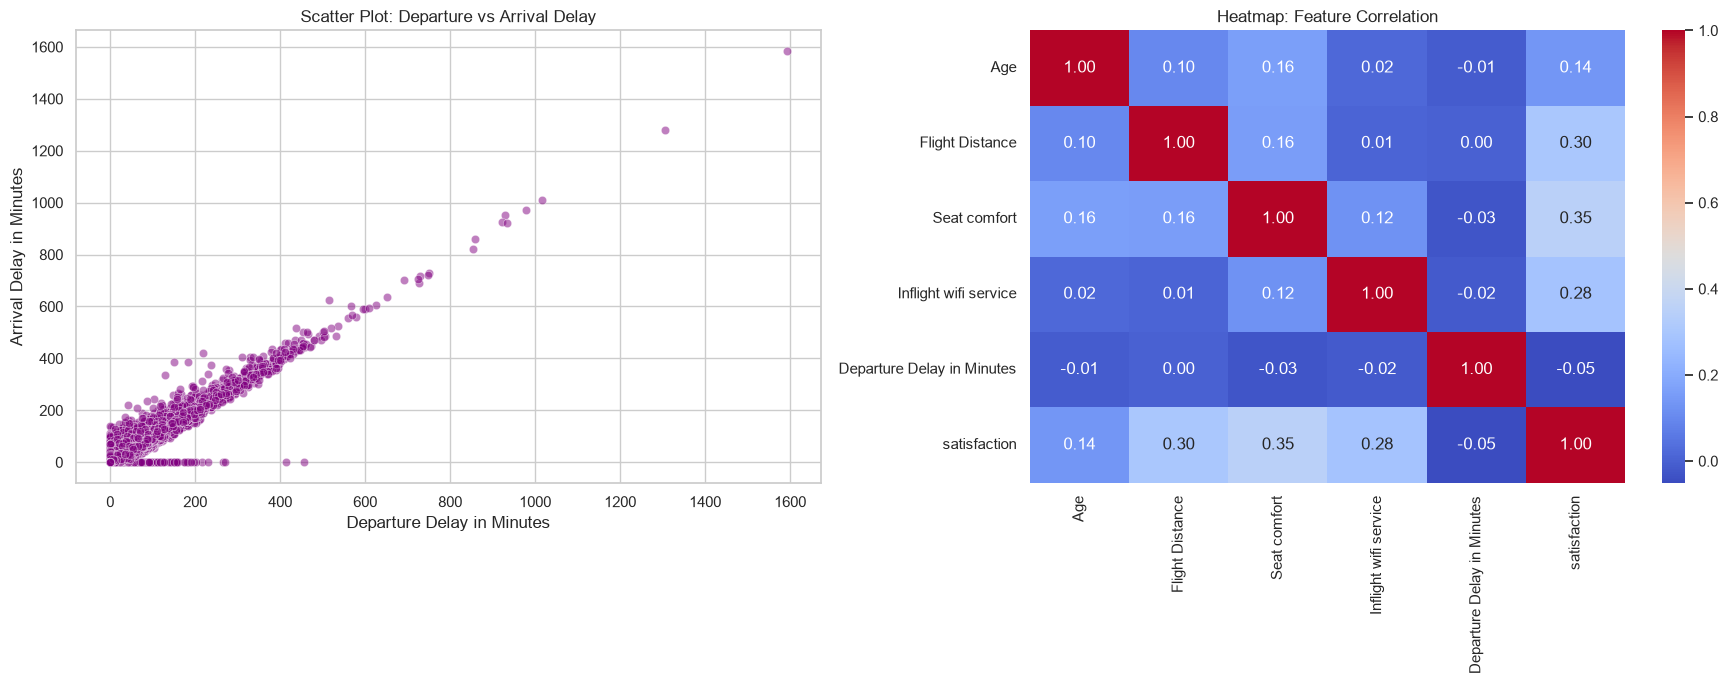

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Scatter Plot Departure and Arrival Delay
sns.scatterplot(x='Departure Delay in Minutes', y='Arrival Delay in Minutes', data=train_df, alpha=0.5, ax=axes[0], color='purple')
axes[0].set_title('Scatter Plot: Departure vs Arrival Delay')

# Heatmap: Correlation Matrix
subset_cols = ['Age', 'Flight Distance', 'Seat comfort', 'Inflight wifi service', 'Departure Delay in Minutes', 'satisfaction']
sns.heatmap(train_df[subset_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1])
axes[1].set_title('Heatmap: Feature Correlation')

plt.tight_layout()
plt.show()

In [39]:
#Hypothesis Testing
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.weightstats import ztest

def format_p(p_val):
    if p_val < 0.0001:
        return "< 0.0001 (Highly Significant)"
    else:
        return f"{p_val:.4f}"



# 1. Z-TEST: Does average Age differ between Satisfied (1) and Dissatisfied (0) passengers?
satisfied_age = train_df[train_df['satisfaction'] == 1]['Age'].dropna()
dissatisfied_age = train_df[train_df['satisfaction'] == 0]['Age'].dropna()

z_stat, p_val_z = ztest(satisfied_age, dissatisfied_age)
print("1. Z-Test (Age vs Satisfaction):")
print(f"   Z-statistic = {z_stat:.2f} | P-value = {format_p(p_val_z)}")
print("   Conclusion: Passenger age significantly impacts satisfaction levels.\n")


# 2. CHI-SQUARE TEST: Is Travel Class associated with Satisfaction?
contingency_table = pd.crosstab(train_df['Class'], train_df['satisfaction'])
chi2, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)

print("2. Chi-Square (Class vs Satisfaction):")
print(f"   Chi2 = {chi2:.2f} | P-value = {format_p(p_val_chi2)}")
print("   Conclusion: Travel class (Eco, Business) is heavily associated with satisfaction.\n")

print("   Conclusion: Flight distances are significantly different for each travel class.\n")

# 3. ANOVA: Does Flight Distance vary significantly across the 3 Travel Classes?
class_0 = train_df[train_df['Class'] == 0]['Flight Distance'].dropna()
class_1 = train_df[train_df['Class'] == 1]['Flight Distance'].dropna()
class_2 = train_df[train_df['Class'] == 2]['Flight Distance'].dropna()

f_stat, p_val_f = stats.f_oneway(class_0, class_1, class_2)
print("3. ANOVA (Flight Distance across Classes):")
print(f"   F-statistic = {f_stat:.2f} | P-value = {format_p(p_val_f)}")
print("   Conclusion: Flight distances are significantly different for each travel class.\n")

1. Z-Test (Age vs Satisfaction):
   Z-statistic = 44.64 | P-value = < 0.0001 (Highly Significant)
   Conclusion: Passenger age significantly impacts satisfaction levels.

2. Chi-Square (Class vs Satisfaction):
   Chi2 = 26471.86 | P-value = < 0.0001 (Highly Significant)
   Conclusion: Travel class (Eco, Business) is heavily associated with satisfaction.

   Conclusion: Flight distances are significantly different for each travel class.

3. ANOVA (Flight Distance across Classes):
   F-statistic = 14481.78 | P-value = < 0.0001 (Highly Significant)
   Conclusion: Flight distances are significantly different for each travel class.



In [40]:
# Predicting Arrival Delay based on Departure Delay
X_train_data = train_df[['Departure Delay in Minutes']]
y_train_data = train_df['Arrival Delay in Minutes']
X_test_data = test_df[['Departure Delay in Minutes']]
y_test_data = test_df['Arrival Delay in Minutes']

#Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train_data, y_train_data)
y_pred_lr = lin_reg.predict(X_test_data)

print(f"Coefficient (Slope): {lin_reg.coef_[0]:.2f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test_data, y_pred_lr):.2f}")
print(f"R-squared Score (Accuracy): {r2_score(y_test_data, y_pred_lr) * 100:.2f}%")

Coefficient (Slope): 0.97
Mean Squared Error (MSE): 121.70
R-squared Score (Accuracy): 91.33%


--- Random Forest Regressor: Predicting Arrival Delay ---

Mean Squared Error (MSE): 122.31
Random Forest Score (Accuracy): 91.29%
Logistic Regression: Predicting Passenger Satisfaction

Classification Accuracy: 87.13%



<Figure size 800x600 with 0 Axes>

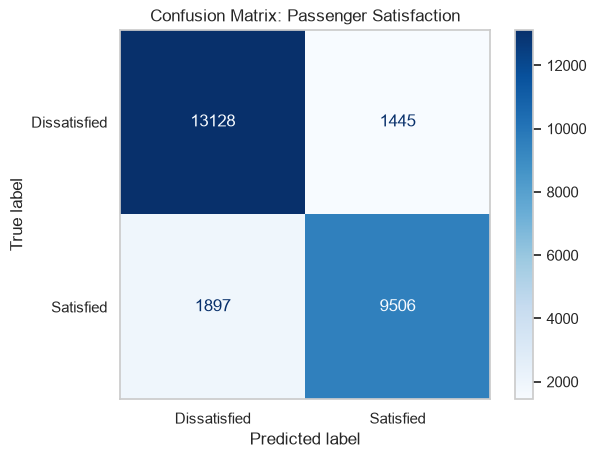

In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("--- Random Forest Regressor: Predicting Arrival Delay ---\n")

X_train_rf = train_df[['Departure Delay in Minutes']]
y_train_rf = train_df['Arrival Delay in Minutes']
X_test_rf = test_df[['Departure Delay in Minutes']]
y_test_rf = test_df['Arrival Delay in Minutes']

# 2. Train the Random Forest Model
# n_estimators=50 builds 50 trees
rf_model = RandomForestRegressor(n_estimators=50, random_state=42)
rf_model.fit(X_train_rf, y_train_rf)

y_pred_rf = rf_model.predict(X_test_rf)

mse_rf = mean_squared_error(y_test_rf, y_pred_rf)
r2_rf = r2_score(y_test_rf, y_pred_rf)

print(f"Mean Squared Error (MSE): {mse_rf:.2f}")
print(f"Random Forest Score (Accuracy): {r2_rf * 100:.2f}%")

print("Logistic Regression: Predicting Passenger Satisfaction\n")
X_train_clf = train_df.drop(columns=['satisfaction'])
X_test_clf = test_df.drop(columns=['satisfaction'])

y_train_clf = train_df['satisfaction'].astype(int)
y_test_clf = test_df['satisfaction'].astype(int)

# Train Model
log_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=5000, random_state=42))
])
log_reg.fit(X_train_clf, y_train_clf)

# Predict & Evaluate
y_pred_clf = log_reg.predict(X_test_clf)

clf_accuracy = accuracy_score(y_test_clf, y_pred_clf)
print(f"Classification Accuracy: {clf_accuracy * 100:.2f}%\n")

# Confusion Matrix
cm = confusion_matrix(y_test_clf, y_pred_clf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Dissatisfied', 'Satisfied'])

plt.figure(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix: Passenger Satisfaction')
plt.grid(False)
plt.show()

In [42]:
prediction_results = X_test_clf.copy()
prediction_results['Actual_Satisfaction'] = y_test_clf
prediction_results['Predicted_Satisfaction'] = y_pred_clf

label_map = {0: 'Dissatisfied', 1: 'Satisfied'}
prediction_results['Actual_Satisfaction'] = prediction_results['Actual_Satisfaction'].map(label_map)
prediction_results['Predicted_Satisfaction'] = prediction_results['Predicted_Satisfaction'].map(label_map)

print("\nPassenger Satisfaction: Actual vs Predicted ")
print(prediction_results[['Age', 'Class', 'Flight Distance', 'Actual_Satisfaction', 'Predicted_Satisfaction']].head(15))

delay_results = X_test_data.copy()
delay_results['Actual_Arrival_Delay'] = y_test_data
delay_results['Predicted_Delay (Linear)'] = np.round(y_pred_lr, 1)
delay_results['Predicted_Delay (Random Forest)'] = np.round(y_pred_rf, 1)

print("\nArrival Delay (Minutes): Actual vs Predicted ")
print(delay_results.head(15))

fake_passenger = X_test_clf.iloc[[0]].copy()

#When Fake Passenger Detected making the flight very long
fake_passenger['Flight Distance'] = 5000
fake_passenger['Seat comfort'] = 0
fake_passenger['Inflight wifi service'] = 0

#Predicting what the Fake Passenge rate
new_prediction = log_reg.predict(fake_passenger)
print(f"\nPrediction for our fake, miserable passenger: {'Satisfied' if new_prediction[0] == 1 else 'Dissatisfied'}")


Passenger Satisfaction: Actual vs Predicted 
    Age Class  Flight Distance Actual_Satisfaction Predicted_Satisfaction
0    52     0              160           Satisfied              Satisfied
1    36     2             2863           Satisfied              Satisfied
2    20     0              192        Dissatisfied           Dissatisfied
3    44     2             3377           Satisfied           Dissatisfied
4    49     0             1182           Satisfied           Dissatisfied
5    16     0              311           Satisfied              Satisfied
6    77     2             3987           Satisfied              Satisfied
7    43     2             2556           Satisfied              Satisfied
8    47     0              556           Satisfied              Satisfied
9    46     2             1744           Satisfied              Satisfied
10   47     0             1235           Satisfied           Dissatisfied
11   33     2              325        Dissatisfied           Dissa

In [43]:
print("Pipeline steps:")
print(log_reg.named_steps.keys())

Pipeline steps:
dict_keys(['scaler', 'model'])


In [44]:

import pandas as pd
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression


print("\n--- Final Report ---")

print(classification_report(
    y_test_clf,
    y_pred_clf,
    target_names=['Dissatisfied', 'Satisfied'],
    zero_division=0
))


model = None

for name, step in log_reg.named_steps.items():
    if isinstance(step, LogisticRegression):
        model = step
        print("\nLogistic Regression found:", name)
        break

if model is None:
    raise ValueError(
        "Logistic Regression not found in the Pipeline. "
        "Check your log_reg model."
    )


# Get feature names
if hasattr(X_train_clf, 'columns'):
    feature_names = X_train_clf.columns
else:
    feature_names = [f"Feature_{i}" for i in range(model.coef_.shape[1])]

# Check feature count
if len(feature_names) != model.coef_.shape[1]:
    raise ValueError(
        "Feature count does not match Logistic Regression coefficients. "
        "Check your preprocessing and feature names."
    )

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': model.coef_[0]
})

top_features = coef_df.sort_values(
    by='Importance',
    ascending=False
)


print("\n--- What Actually Drives Passenger Satisfaction? ---")

print("\nTop 3 Happy Passengers (Positive Impact):")

print(f"{'Feature':<35} {'Importance':>10}")
print("-" * 46)

for _, row in top_features.head(3).iterrows():
    print(f"{row['Feature']:<35} {row['Importance']:>10.4f}")

print("\nTop 3 Angry Passengers (Negative Impact):")

print(f"{'Feature':<35} {'Importance':>10}")
print("-" * 46)

for _, row in top_features.tail(3).sort_values(
    by='Importance'
).iterrows():
    print(f"{row['Feature']:<35} {row['Importance']:>10.4f}")



print("\n--- All Feature Importance Scores ---")

print(
    coef_df.sort_values(
        by='Importance',
        ascending=False
    ).to_string(index=False)
)

print("\n--- Analysis Completed Successfully! ---")



--- Final Report ---


              precision    recall  f1-score   support

Dissatisfied       0.87      0.90      0.89     14573
   Satisfied       0.87      0.83      0.85     11403

    accuracy                           0.87     25976
   macro avg       0.87      0.87      0.87     25976
weighted avg       0.87      0.87      0.87     25976


Logistic Regression found: model

--- What Actually Drives Passenger Satisfaction? ---

Top 3 Happy Passengers (Positive Impact):
Feature                             Importance
----------------------------------------------
Type of Travel                          1.2690
Online boarding                         0.8328
Customer Type                           0.7730

Top 3 Angry Passengers (Negative Impact):
Feature                             Importance
----------------------------------------------
Arrival Delay in Minutes               -0.3426
Departure/Arrival time convenient      -0.1924
Ease of Online booking                 -0.1922

--- All Feature Importance S